In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("C:/Users/Marun Yory/Desktop/oil_sales_prediction/oil_sales_data.csv/oil_sales_assignment_dataset.csv")

In [4]:
df.head()

,city,store_name,manufacturer,brand,class,size,sku,price_bracket,year,month,value_sales,volume_sales,average_price
0,AL BAHA,HM No 57296 GS-CENTER-AL BAHA MAIN RD AL BAHA,NOVA FOODS,LARA,COCONUT,0.75L,LARA COCONUT 0.75L TWIN PACK,21-30,2024,12,830.86,30.1,27.6
1,AL KHARJ,HM No 55697 GS-CENTER-AL KHARJ MAIN RD AL K...,PALM & GRAIN GROUP,NAJMA,CANOLA,0.5L,NAJMA CANOLA 0.5L TWIN PACK,41-50,2024,10,373.10,9.1,41.0
2,RIYADH,HM No 86781 GS-CENTER-RIYADH MAIN RD RIYADH,AL HILAL INDUSTRIES,BAYTNA,SUNFLOWER,0.75L,BAYTNA SUNFLOWER 0.75L ECO,101+,2023,1,171.70,1.7,101.0
3,DAMMAM,HM No 95753 GS-CENTER-DAMMAM MAIN RD DAMMAM,PALM & GRAIN GROUP,NOUR,CORN,0.6L,NOUR CORN 0.6L TWIN PACK,61-70,2022,2,1226.10,20.1,61.0
4,JAZAN,HM No 56338 GS-CENTER-JAZAN MAIN RD JAZAN,DESERT SUN CO,NOUR,VEGETABLE,1L,NOUR VEGETABLE 1L,81-90,2024,2,996.30,12.3,81.0


In [5]:
df.shape

(2000, 13)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   city           2000 non-null   str    
 1   store_name     2000 non-null   str    
 2   manufacturer   2000 non-null   str    
 3   brand          2000 non-null   str    
 4   class          2000 non-null   str    
 5   size           2000 non-null   str    
 6   sku            2000 non-null   str    
 7   price_bracket  2000 non-null   str    
 8   year           2000 non-null   int64  
 9   month          2000 non-null   int64  
 10  value_sales    2000 non-null   float64
 11  volume_sales   2000 non-null   float64
 12  average_price  2000 non-null   float64
dtypes: float64(3), int64(2), str(8)
memory usage: 203.3 KB


In [8]:
df.isnull().sum()

city             0
store_name       0
manufacturer     0
brand            0
class            0
size             0
sku              0
price_bracket    0
year             0
month            0
value_sales      0
volume_sales     0
average_price    0
dtype: int64

In [9]:
df.columns

Index(['city', 'store_name', 'manufacturer', 'brand', 'class', 'size', 'sku',
       'price_bracket', 'year', 'month', 'value_sales', 'volume_sales',
       'average_price'],
      dtype='str')

In [10]:
df['manufacturer'].value_counts()

manufacturer
AL HILAL INDUSTRIES    272
PALM & GRAIN GROUP     259
NAJDI CONSUMER         256
SAHARA EDIBLES         256
BLUE OASIS CO          253
DESERT SUN CO          243
ARABIAN HARVEST CO     240
NOVA FOODS             221
Name: count, dtype: int64

In [11]:
df.describe()

,year,month,value_sales,volume_sales,average_price
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,2022.990500,6.639500,614.839355,9.972100,60.990230
std,0.820211,3.468942,750.794991,9.862369,29.457029
min,2022.000000,1.000000,6.960000,0.500000,11.000000
25%,2022.000000,4.000000,132.000000,2.900000,37.337500
50%,2023.000000,7.000000,368.320000,7.000000,61.000000
75%,2024.000000,10.000000,794.100000,13.800000,81.000000
max,2024.000000,12.000000,6253.200000,81.700000,140.000000


In [12]:
categorical_cols = df.select_dtypes(["object"], "category").columns
categorical_cols

Index(['city', 'store_name', 'manufacturer', 'brand', 'class', 'size', 'sku',
       'price_bracket'],
      dtype='str')

In [13]:
numerical_cols = df.select_dtypes(['int64', 'float64']).columns
numerical_cols

Index(['year', 'month', 'value_sales', 'volume_sales', 'average_price'], dtype='str')

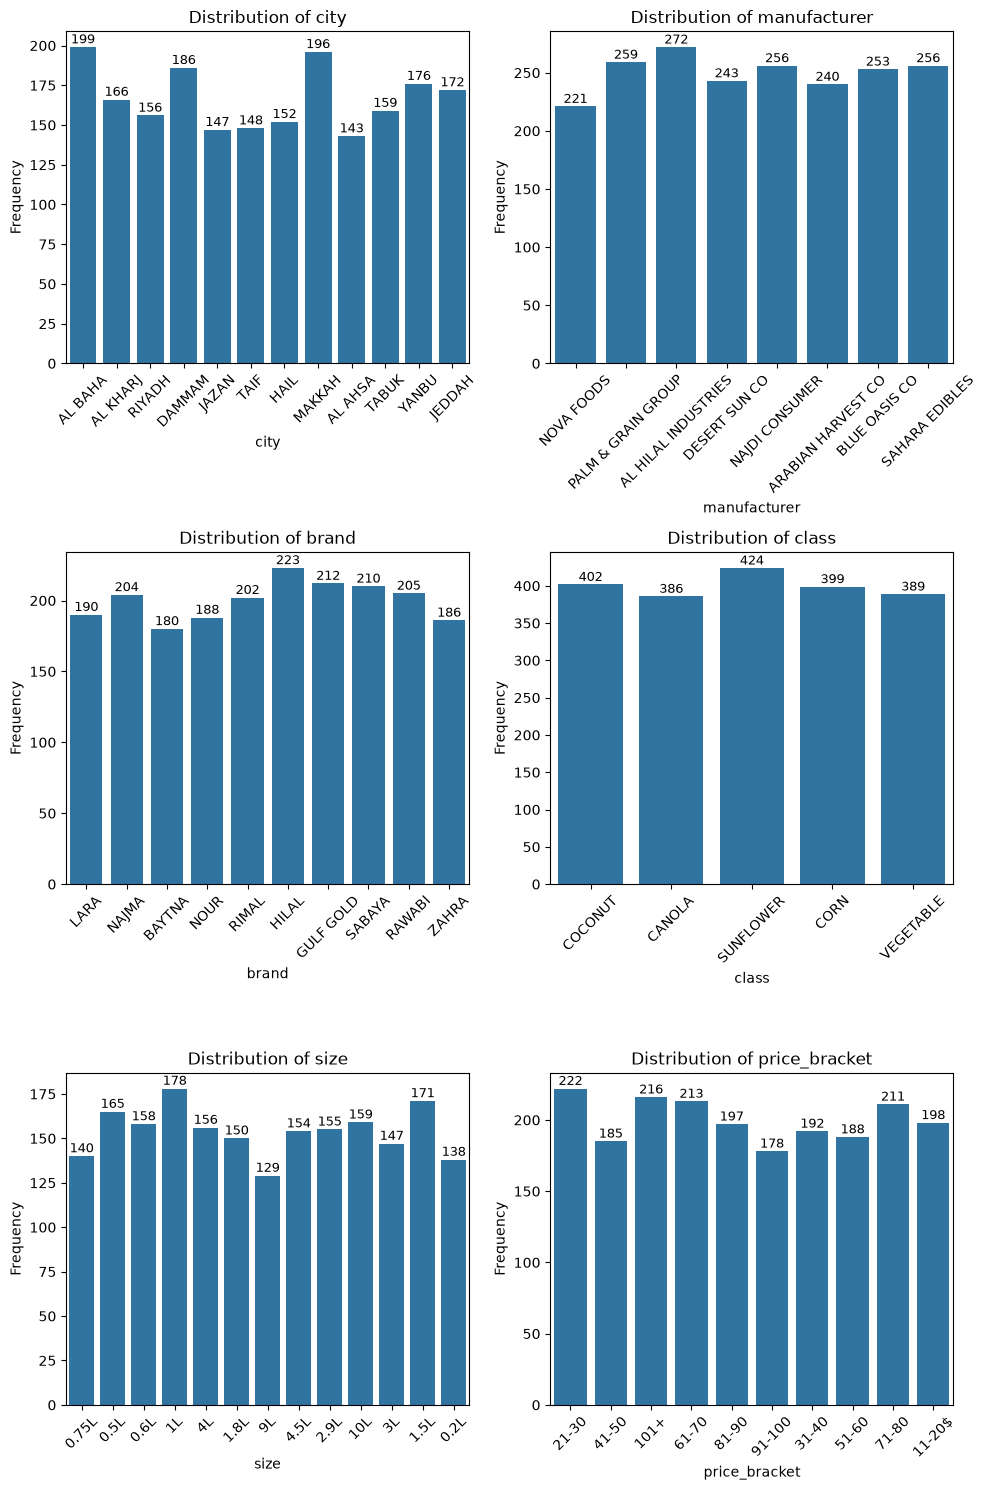

In [15]:
cols = ['city', 'manufacturer', 'brand', 'class', 'size', 'price_bracket']
plt.figure(figsize=(10, 15))
for i, col in enumerate(cols, 1):
    plt.subplot(3, 2, i)
    ax = sns.countplot(data = df, x = col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    for p in ax.patches:
        height = p.get_height()
        ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
    plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [16]:
# Color Palettes
palette1 = "viridis"
palette2 = "Set2"
palette3 = "coolwarm"
palette4 = "plasma"
palette5 = "magma"
palette6 = "tab20"
palette7 = "Spectral"

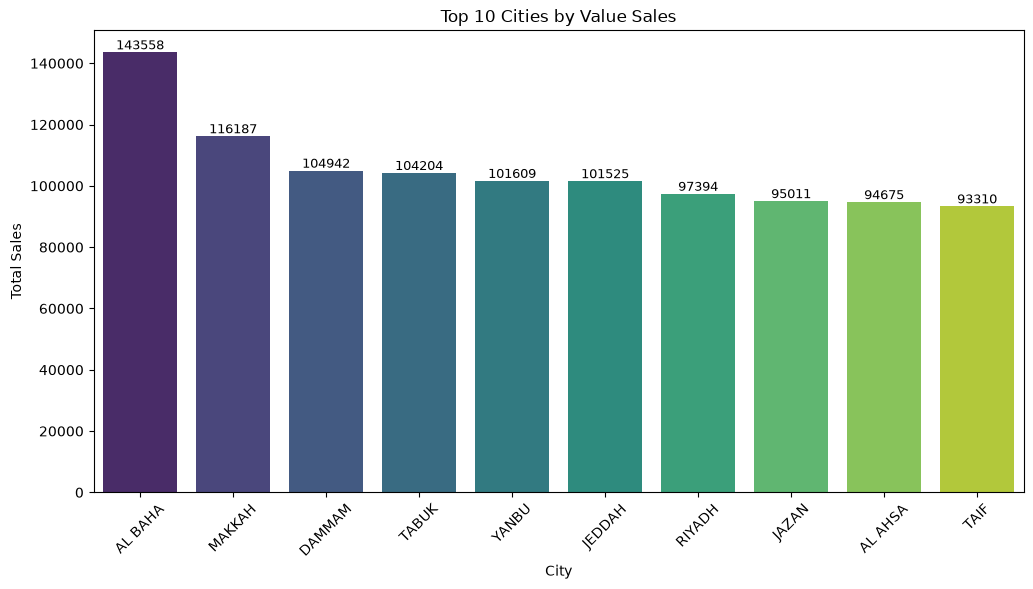

In [ ]:
# 1. Top 10 Cities by Sales
city_sales = df.groupby("city")["value_sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
ax = sns.barplot(
    x=city_sales.index,
    y=city_sales.values,
    palette=palette1
)
for p in ax.patches:
        height = p.get_height()
        ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation=45)
plt.title("Top 10 Cities by Value Sales")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.show()

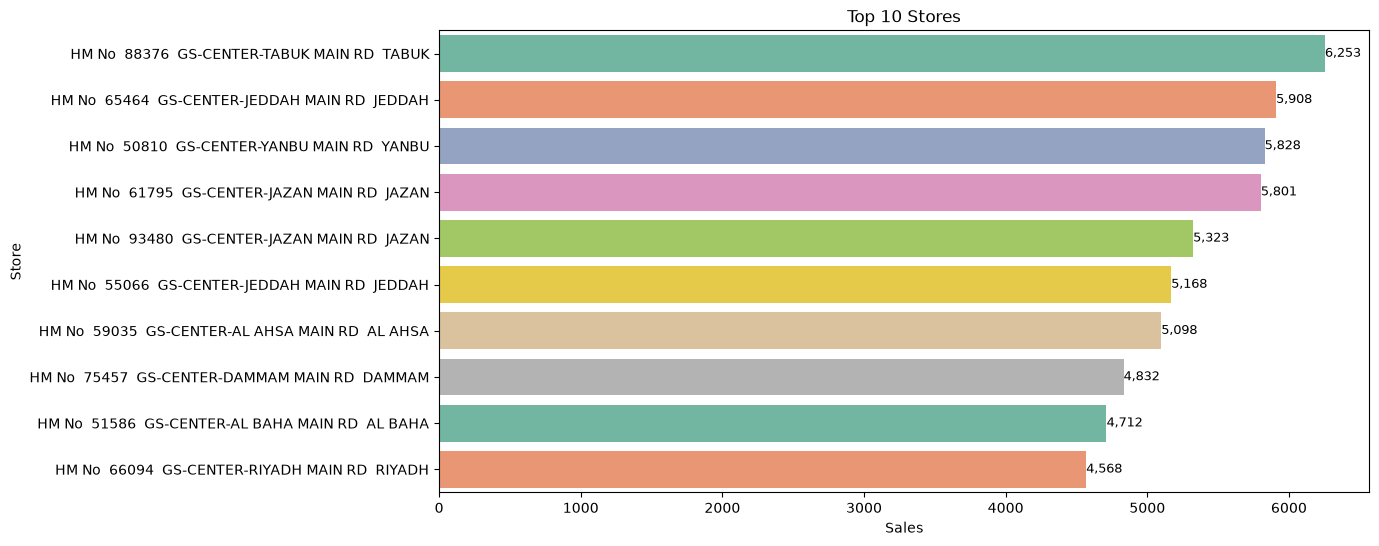

In [ ]:
# 2. Top Stores
store_sales = df.groupby("store_name")["value_sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
ax = sns.barplot(
    x=store_sales.values,
    y=store_sales.index,
    palette=palette2
)
for p in ax.patches:
    ax.text(
        p.get_width() + 0.5,
        p.get_y() + p.get_height()/2,
        f'{p.get_width():,.0f}',
        va='center',
        fontsize=9
    )
plt.title("Top 10 Stores")
plt.xlabel("Sales")
plt.ylabel("Store")
plt.show()

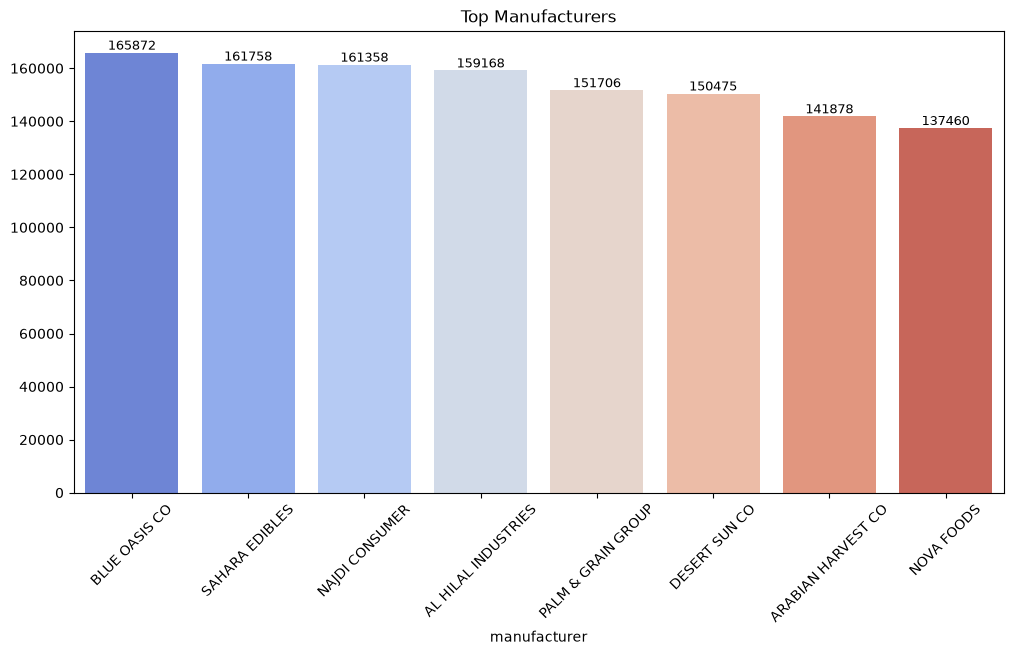

In [ ]:
# 3. Manufacturer Sales
manufacturer_sales = df.groupby("manufacturer")["value_sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
ax = sns.barplot(
    x=manufacturer_sales.index,
    y=manufacturer_sales.values,
    palette=palette3
)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height+0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation=45)
plt.title("Top Manufacturers")
plt.show()

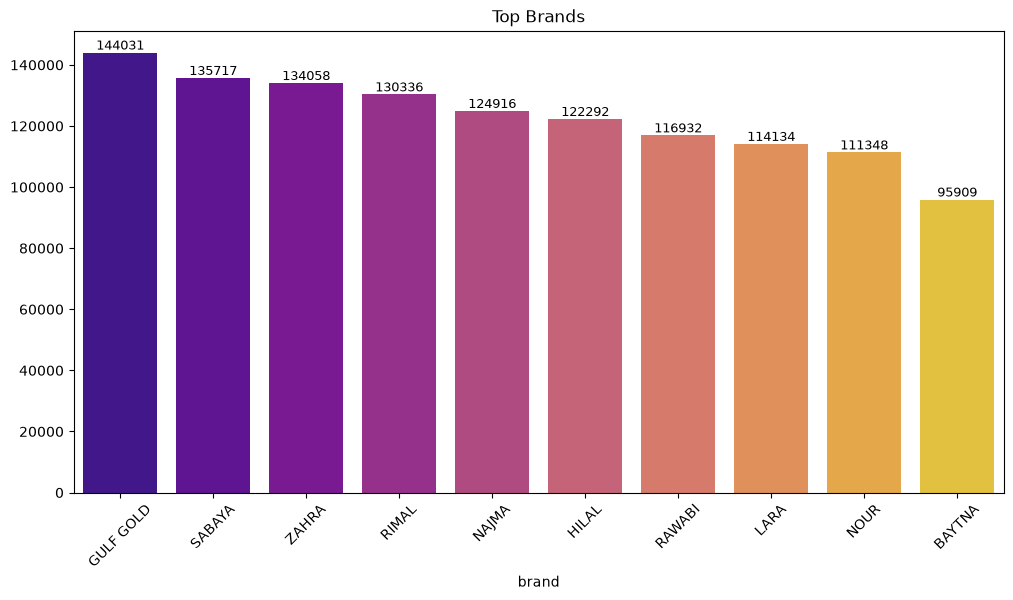

In [ ]:
# 4. Brand Sales
brand_sales = df.groupby("brand")["value_sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
ax = sns.barplot(
    x=brand_sales.index,
    y=brand_sales.values,
    palette=palette4
)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height),ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation=45)
plt.title("Top Brands")
plt.show()

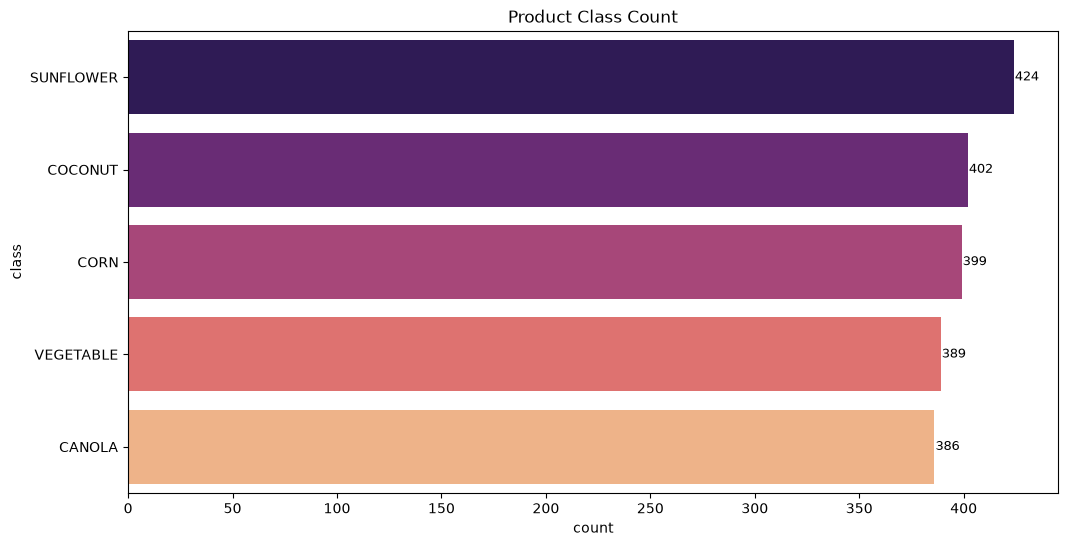

In [ ]:
# 5. Product Class Count
plt.figure(figsize=(12,6))
ax = sns.countplot(
    data=df,
    y="class",
    palette=palette5,
    order=df["class"].value_counts().index
)
for p in ax.patches:
    ax.text(
        p.get_width() + 0.5,
        p.get_y() + p.get_height()/2,
        f'{p.get_width():,.0f}',
        va='center',
        fontsize=9
    )
plt.title("Product Class Count")
plt.show()

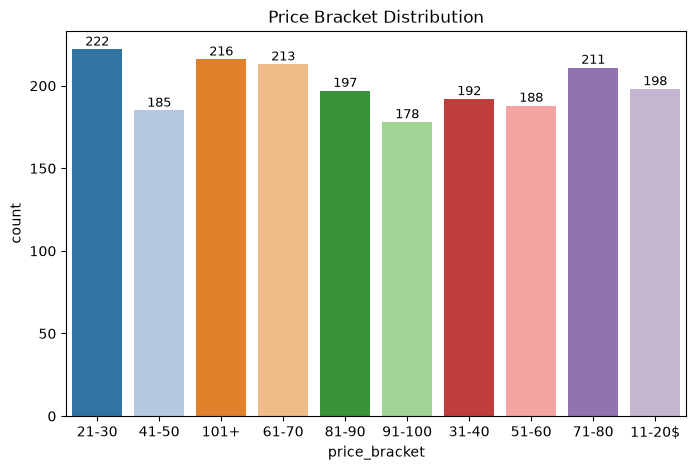

In [ ]:
# 6. Price Bracket Count
plt.figure(figsize=(8,5))
ax = sns.countplot(
    data=df,
    x="price_bracket",
    palette=palette6
)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
plt.title("Price Bracket Distribution")
plt.show()

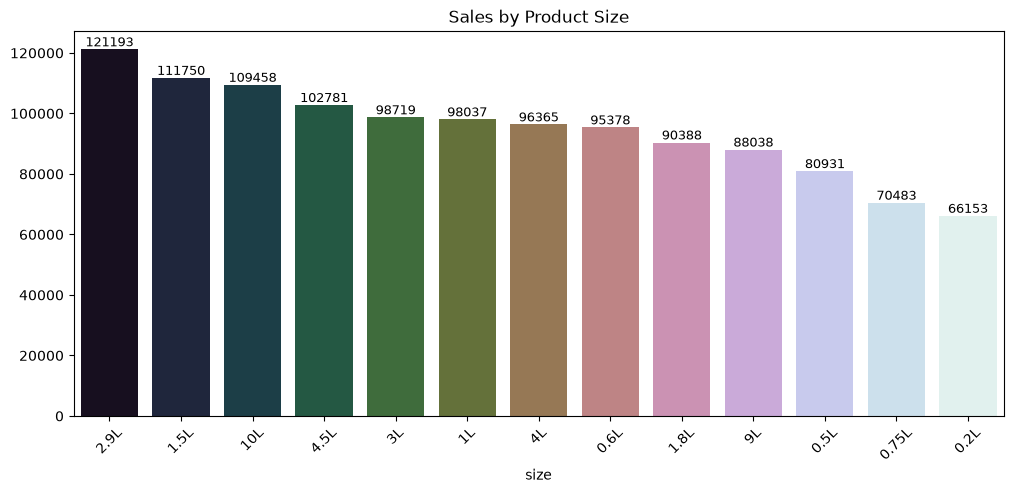

In [ ]:
# 7. Sales by Product Size
size_sales = df.groupby("size")["value_sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))
ax = sns.barplot(
    x=size_sales.index,
    y=size_sales.values,
    palette="cubehelix"
)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation=45)
plt.title("Sales by Product Size")
plt.show()

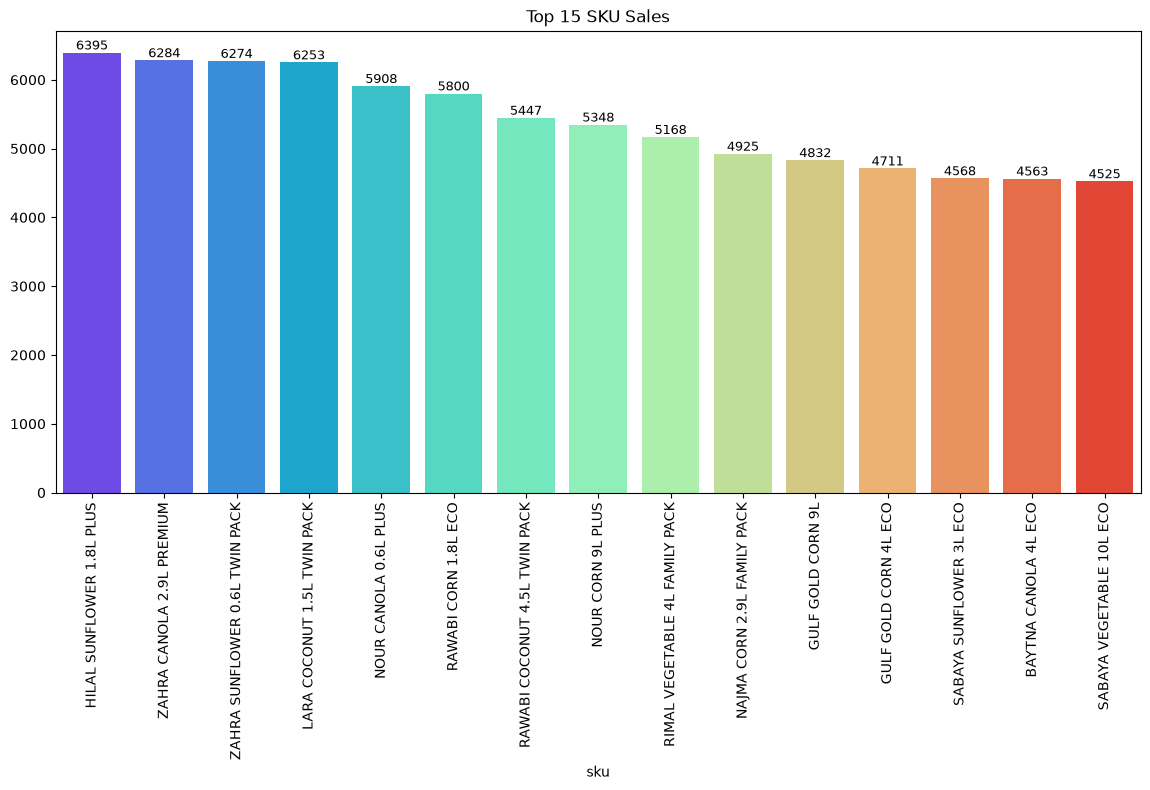

In [ ]:
# 8. Top SKU Sales
sku_sales = df.groupby("sku")["value_sales"].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(14,6))
ax = sns.barplot(
    x=sku_sales.index,
    y=sku_sales.values,
    palette="rainbow"
)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 9)
plt.xticks(rotation=90)
plt.title("Top 15 SKU Sales")
plt.show()

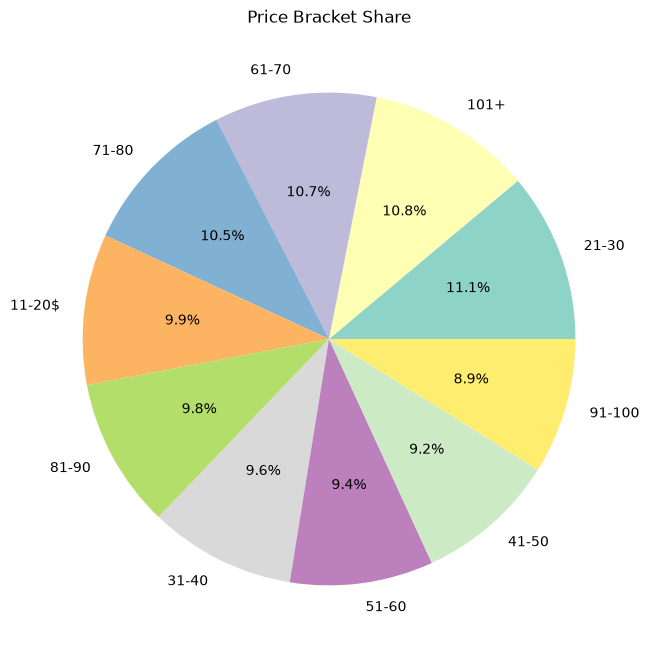

In [39]:
# 9. Pie Chart of Price Bracket
plt.figure(figsize=(8,8))

df["price_bracket"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    cmap="Set3"
)

plt.ylabel("")
plt.title("Price Bracket Share")
plt.show()

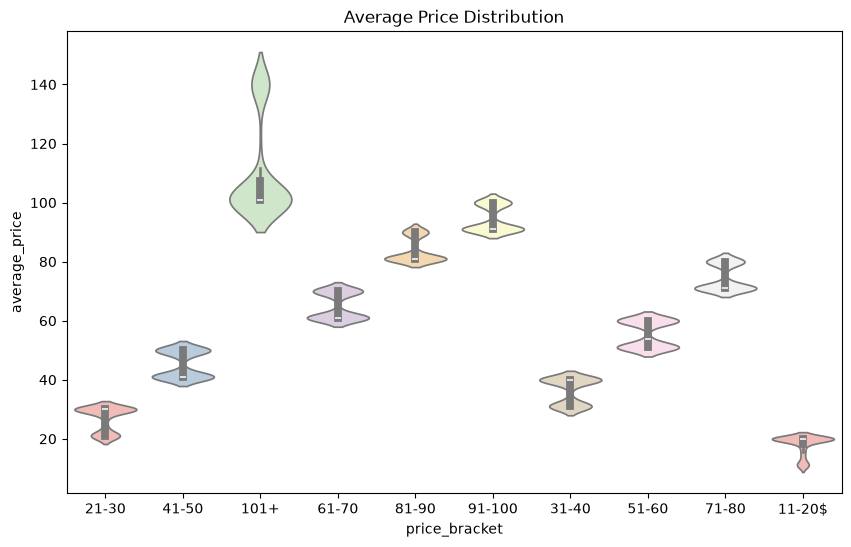

In [ ]:
# 10. Violin Plot
plt.figure(figsize=(10,6))
sns.violinplot(
    data=df,
    x="price_bracket",
    y="average_price",
    palette="Pastel1"
)

plt.title("Average Price Distribution")
plt.show()

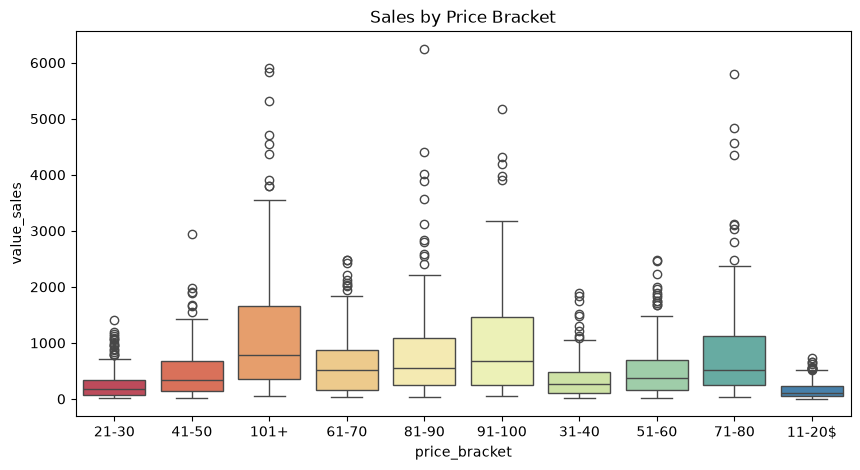

In [41]:
# 11. Sales by Price Bracket
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x="price_bracket",
    y="value_sales",
    palette=palette7
)
plt.title("Sales by Price Bracket")
plt.show()

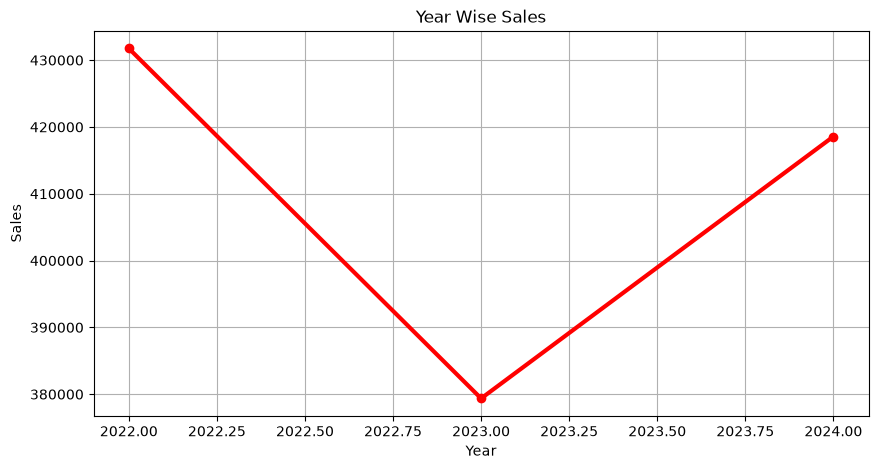

In [42]:
# 12. Year Wise Sales
year_sales = df.groupby("year")["value_sales"].sum()

plt.figure(figsize=(10,5))
plt.plot(
    year_sales.index,
    year_sales.values,
    marker="o",
    linewidth=3,
    color="red"
)
plt.title("Year Wise Sales")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

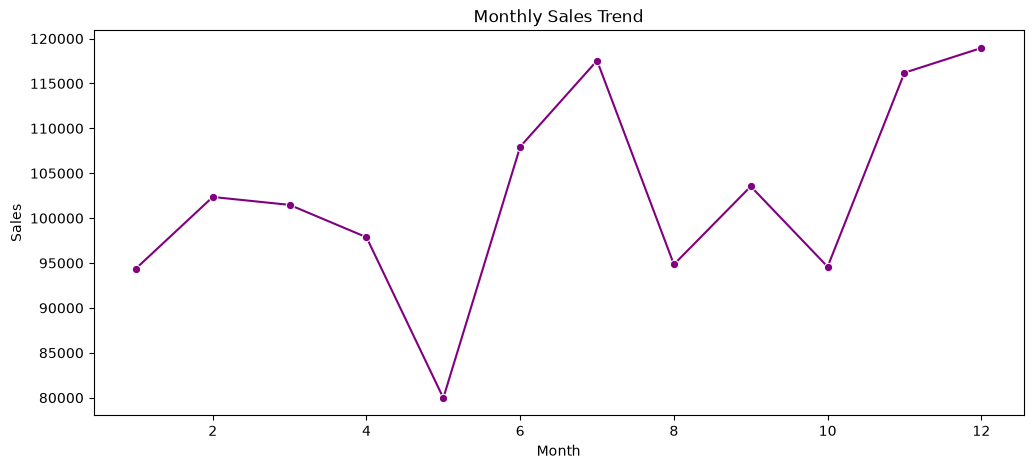

In [43]:
# 13. Monthly Sales
month_sales = df.groupby("month")["value_sales"].sum()

plt.figure(figsize=(12,5))
sns.lineplot(
    x=month_sales.index,
    y=month_sales.values,
    marker="o",
    color="purple"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

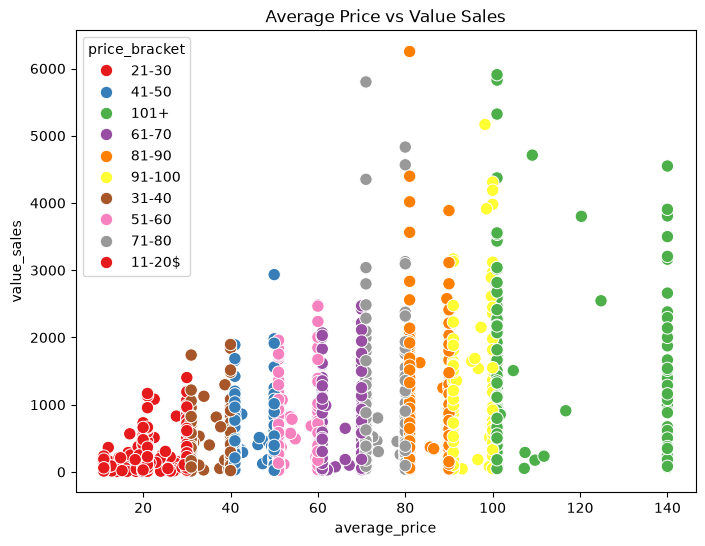

In [44]:
# 14. Average Price vs Sales
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="average_price",
    y="value_sales",
    hue="price_bracket",
    palette="Set1",
    s=80
)
plt.title("Average Price vs Value Sales")
plt.show()

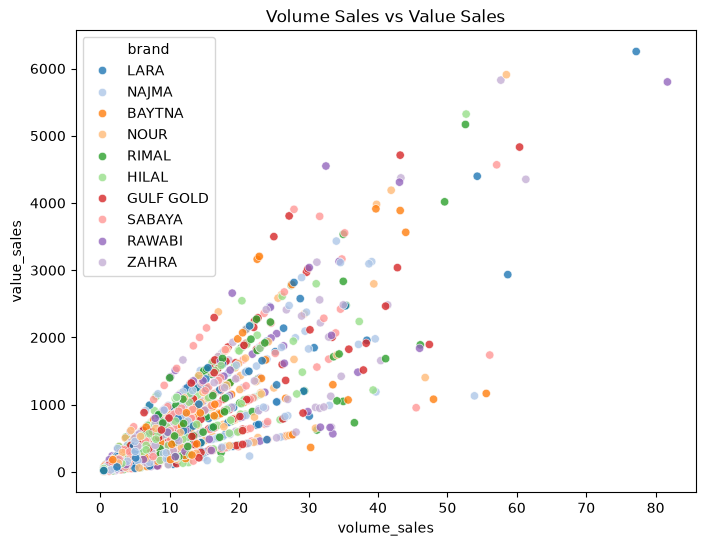

In [45]:
# 15. Volume Sales vs Value Sales
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="volume_sales",
    y="value_sales",
    hue="brand",
    palette="tab20",
    alpha=0.8
)
plt.title("Volume Sales vs Value Sales")
plt.show()

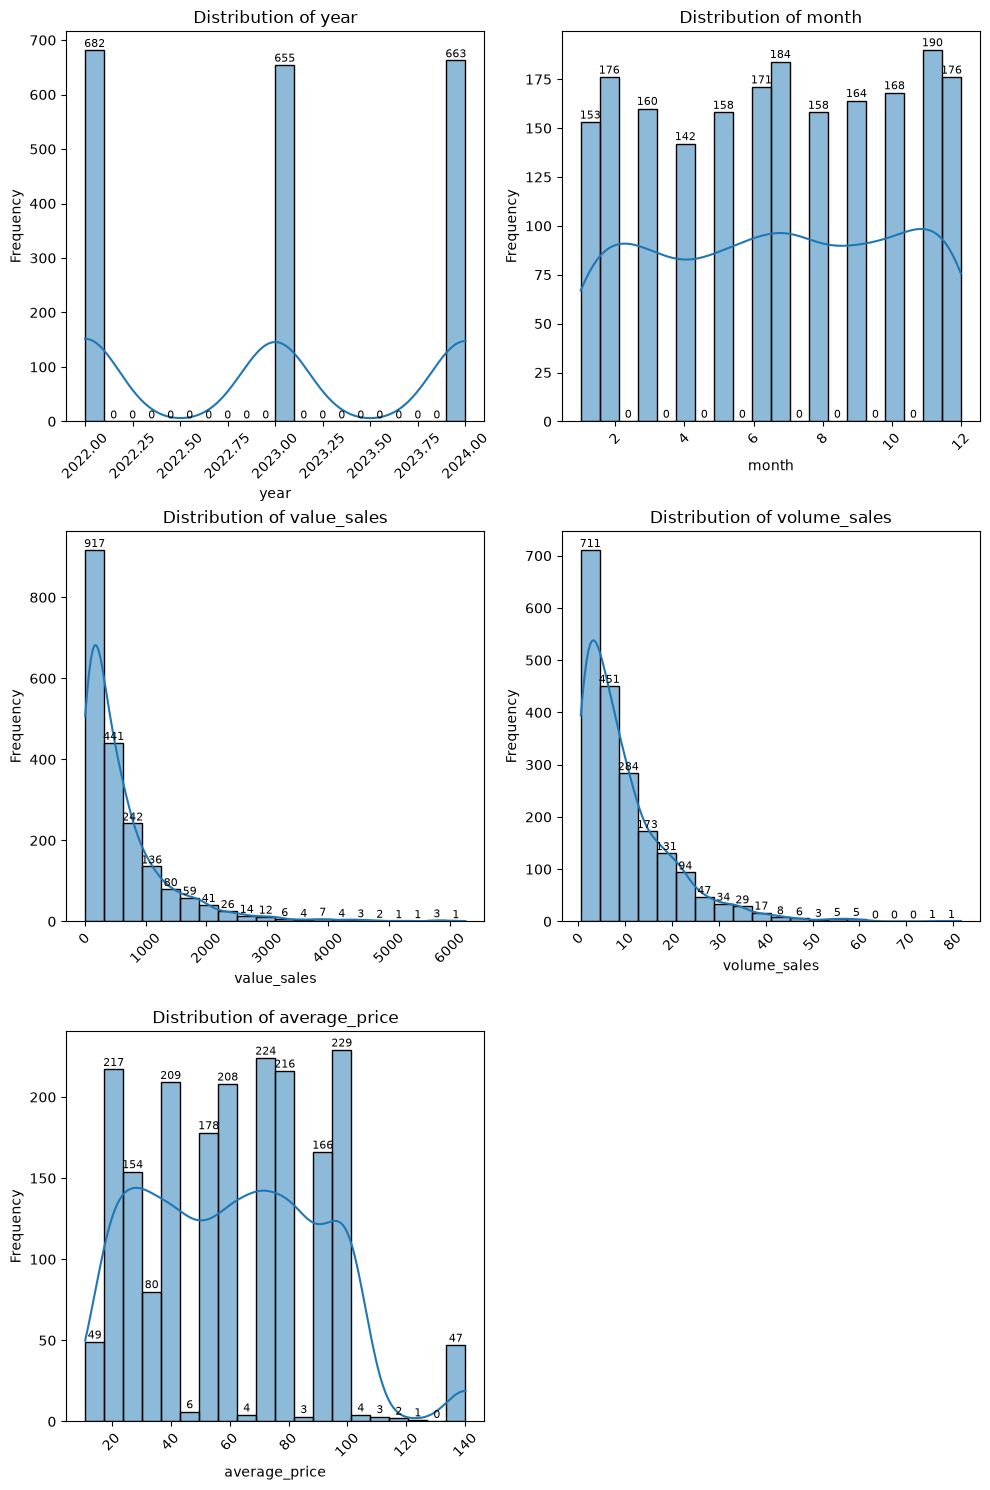

In [46]:
plt.figure(figsize=(10, 15))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 2, i)
    ax = sns.histplot(df[col], kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    for p in ax.patches:
        height = p.get_height()
        ax.text(p.get_x() + p.get_width()/2, height + 0.5, int(height), ha = 'center', va = 'bottom', fontsize = 8)
    plt.xticks(rotation =45)
plt.tight_layout()
plt.show()

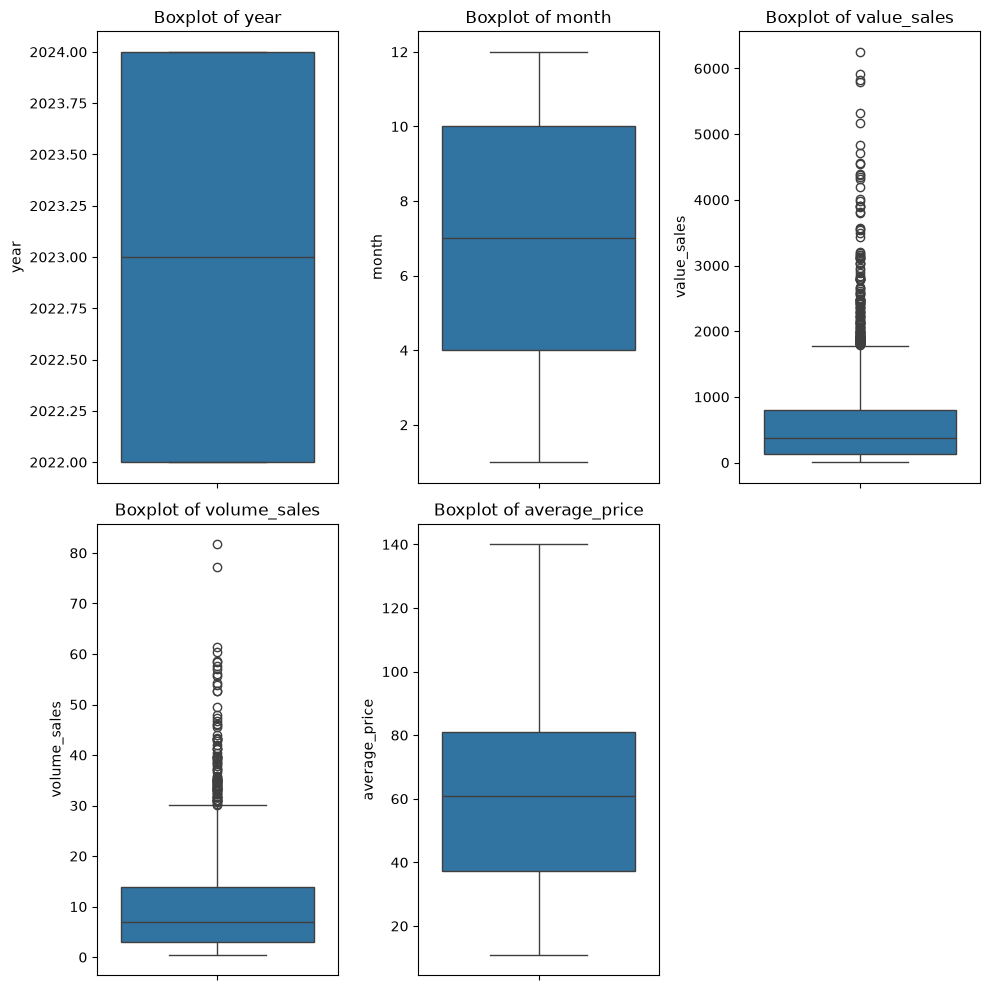

In [47]:
plt.figure(figsize=(10, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot( data=df, y=col)
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

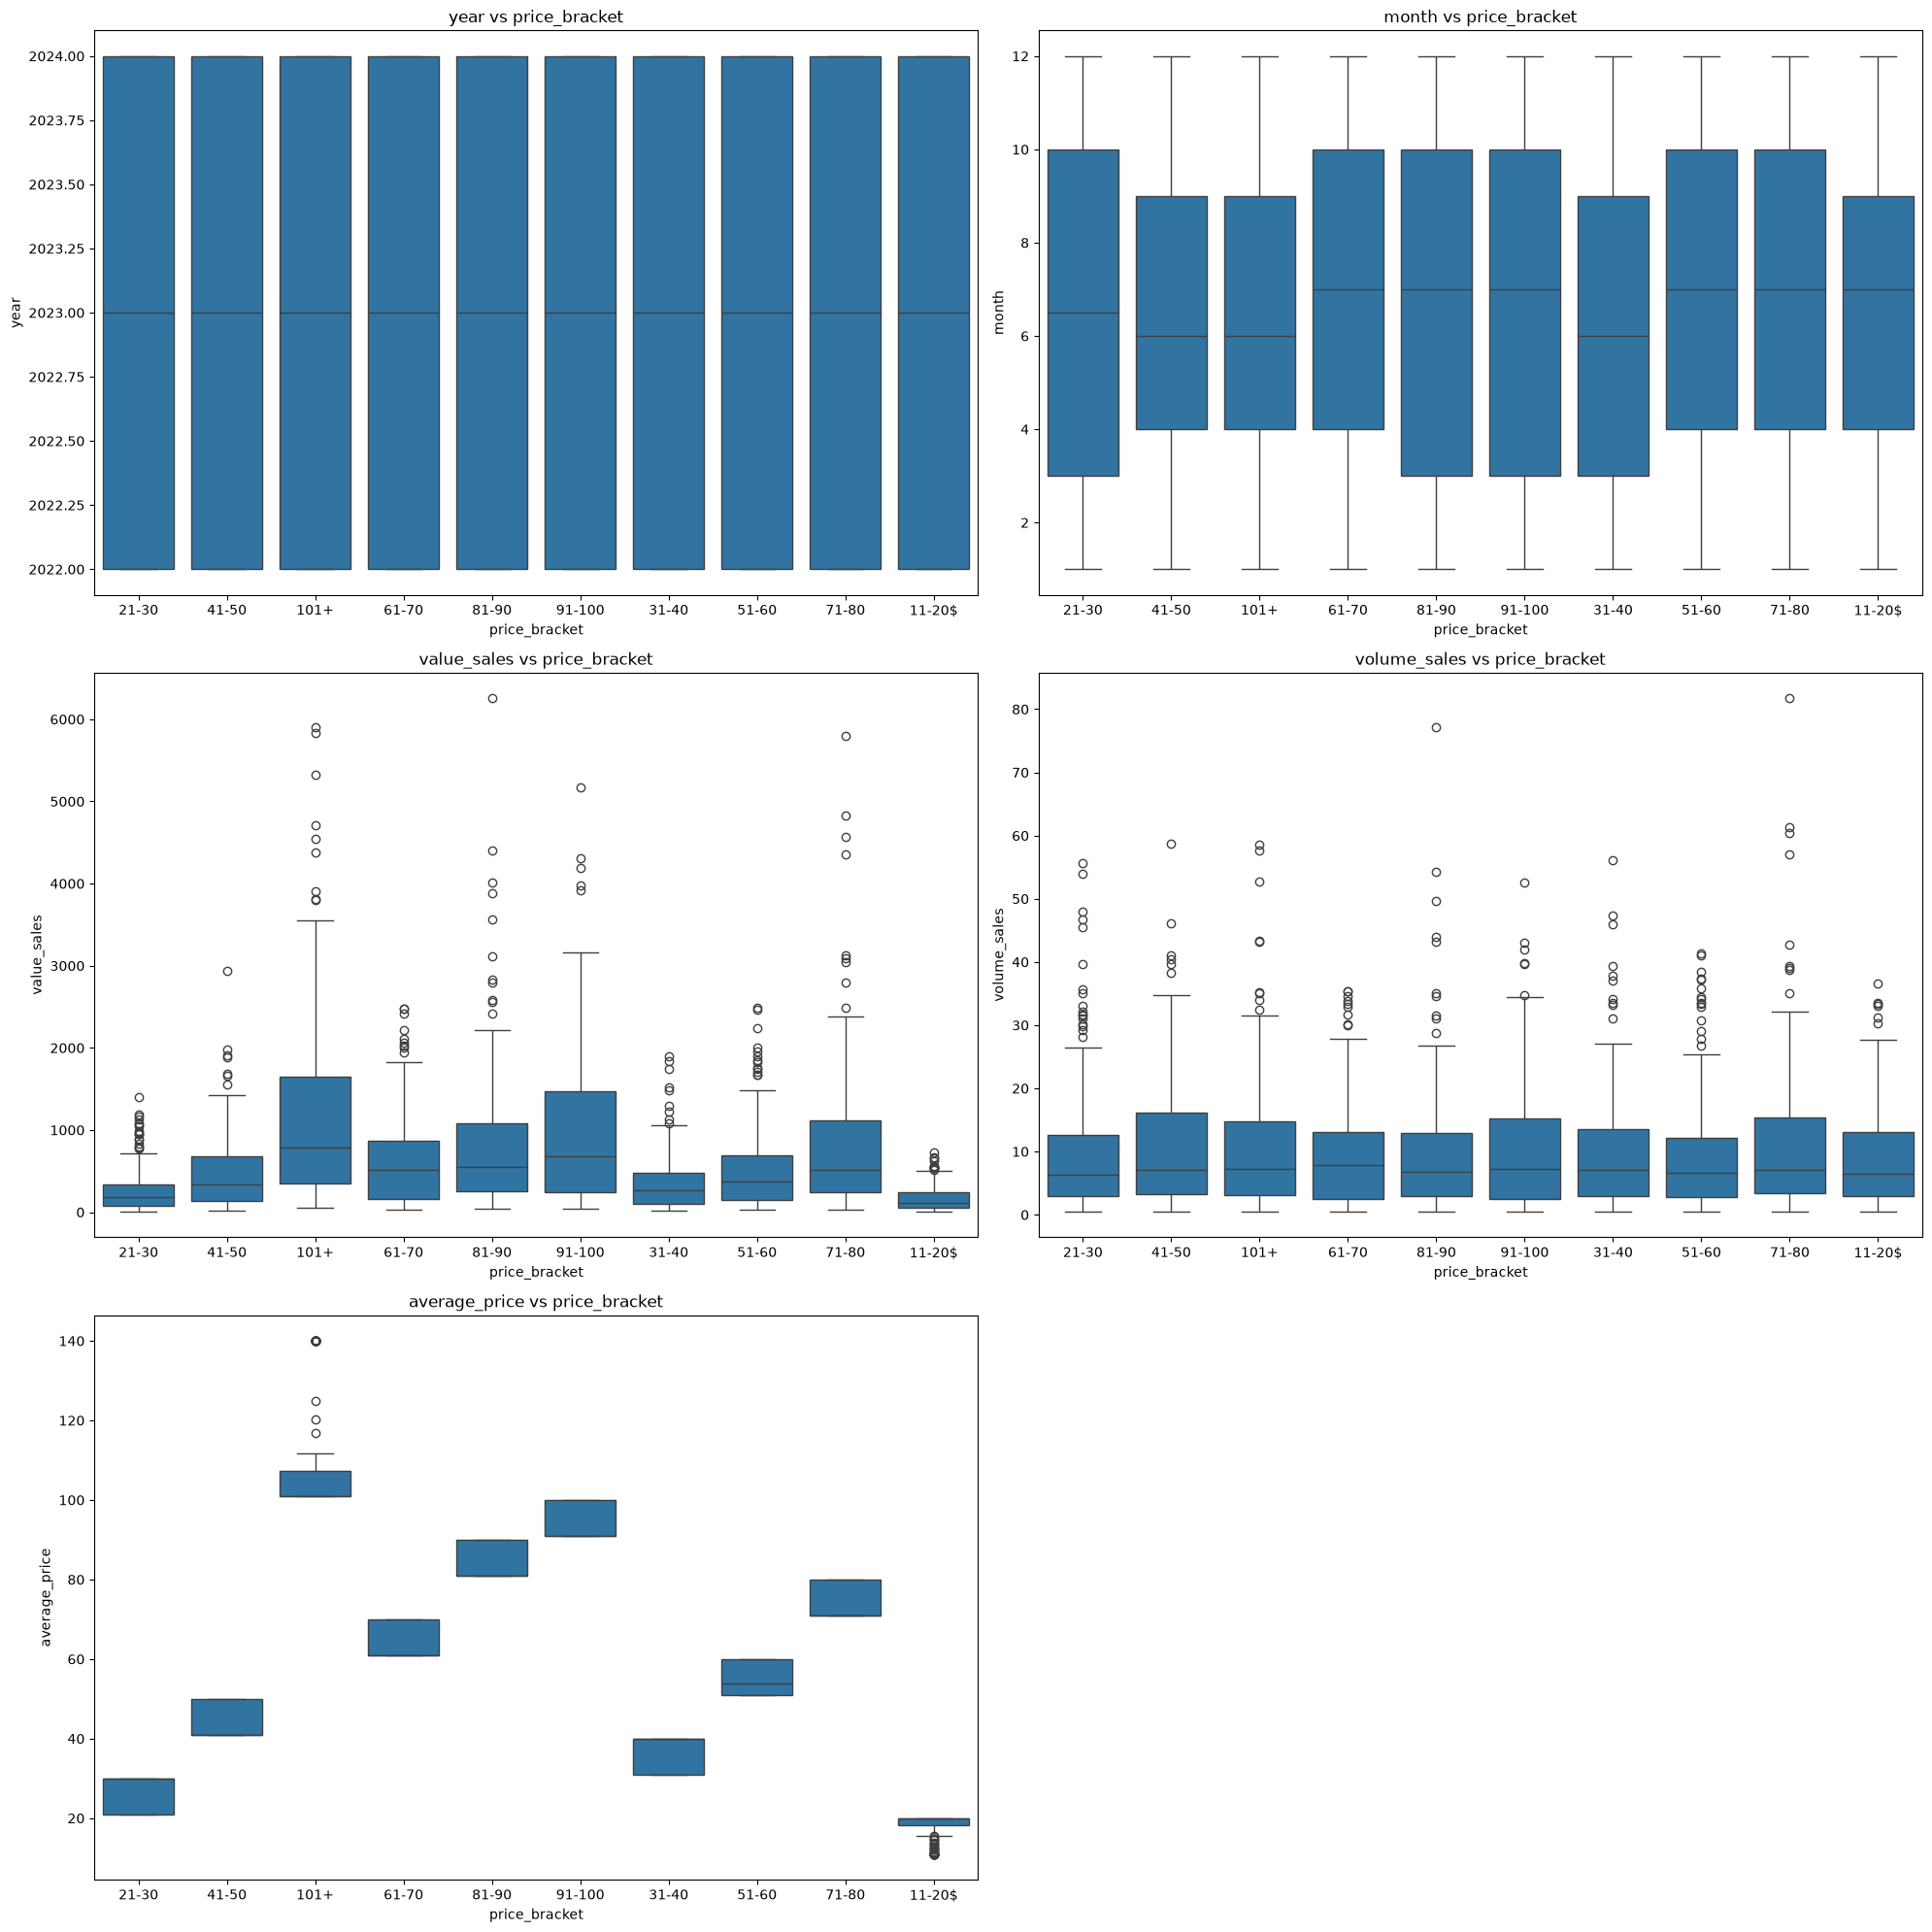

In [48]:
plt.figure(figsize=(20, 20))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 2, i+1)
    sns.boxplot(data = df, y = df[col], x = 'price_bracket')
    plt.title(f'{col} vs price_bracket')
plt.tight_layout()
plt.show()

In [49]:
correlation_matrix = df[numerical_cols].corr()
fig = px.imshow(correlation_matrix, text_auto=True, aspect='auto', color_continuous_scale='RdBu')
fig.update_layout(title = 'Correlation Matrix of Numerical Featurse', height = 700, width = 500)
fig.show()

In [ ]:
%pip install -U nbformat plotly

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [51]:
categorical_cols = df.select_dtypes(['object']).columns
for col in categorical_cols:
    Label_encoders = {}
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    Label_encoders[col] = le

In [52]:
X = df.drop('price_bracket', axis=1)
y = df['price_bracket']

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [54]:
scaler = StandardScaler()

In [55]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [65]:
model = LogisticRegression()

In [66]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [67]:
y_pred = model.predict(X_test_scaled)

In [69]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.73
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89        32
           1       0.90      1.00      0.95        35
           2       0.85      0.89      0.87        46
           3       0.73      0.79      0.76        38
           4       0.84      0.55      0.67        49
           5       0.50      0.38      0.43        37
           6       0.50      0.86      0.63        37
           7       0.77      0.55      0.64        49
           8       0.68      0.72      0.70        39
           9       0.79      0.71      0.75        38

    accuracy                           0.73       400
   macro avg       0.74      0.74      0.73       400
weighted avg       0.74      0.73      0.72       400



In [70]:
model = RandomForestClassifier()

In [74]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [75]:
y_pred = model.predict(X_test)

In [76]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9925
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00        35
           2       1.00      1.00      1.00        46
           3       0.97      1.00      0.99        38
           4       0.98      0.98      0.98        49
           5       1.00      0.95      0.97        37
           6       1.00      1.00      1.00        37
           7       0.98      1.00      0.99        49
           8       1.00      1.00      1.00        39
           9       1.00      1.00      1.00        38

    accuracy                           0.99       400
   macro avg       0.99      0.99      0.99       400
weighted avg       0.99      0.99      0.99       400



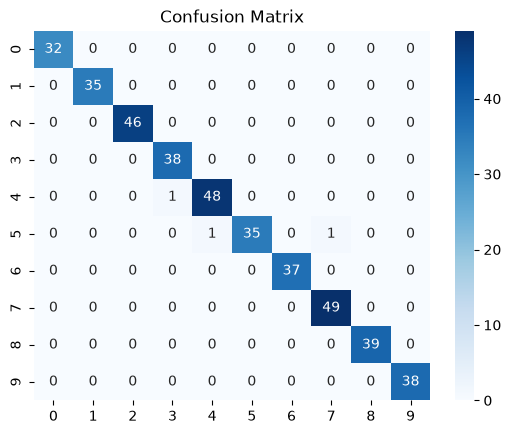

In [77]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [78]:
model = DecisionTreeClassifier()

In [79]:
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [80]:
y_pred = model.predict(X_test)

In [81]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00        35
           2       1.00      1.00      1.00        46
           3       1.00      1.00      1.00        38
           4       1.00      1.00      1.00        49
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        37
           7       1.00      1.00      1.00        49
           8       1.00      1.00      1.00        39
           9       1.00      1.00      1.00        38

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



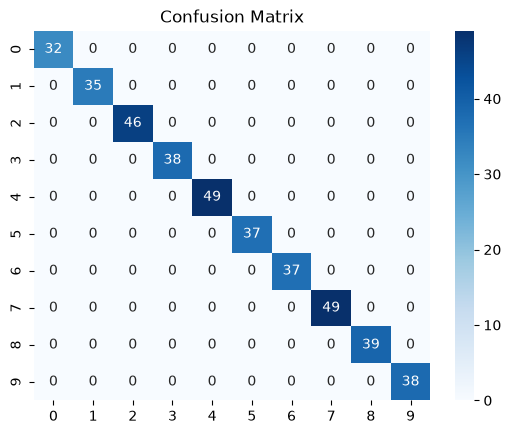

In [82]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap="Blues")
plt.title("Confusion Matrix")
plt.show()